Basic ML (1 real input and 1 real output) - Polinomial regression + Regularization

In [294]:
import numpy as np # numerical things
import numpy.matlib as nml # matricial computations
import matplotlib.pyplot as plt # plots
from sklearn.model_selection import train_test_split

In [295]:
np.random.seed(15)

In [296]:
def oracle(x):
  #return x**2
  return np.sinc(3*x)
  #return np.abs(np.abs(x-.4)-.2) + x/2-.1

In [297]:
n = 20
sigma = 0.1

In [298]:
x = np.random.rand(n)
y = oracle(x) + sigma * np.random.randn(n)

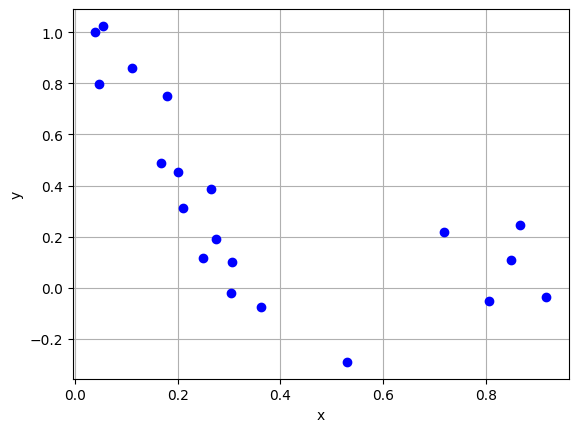

In [299]:
fig, ax = plt.subplots()
ax.plot(x,y, 'bo') # blue points
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.grid() # acrivate the grid
plt.show()

In [300]:
x = np.asmatrix(x).transpose()
y = np.asmatrix(y).transpose()

In [301]:
# Split the data in learning and validation
xl, xv, yl, yv = train_test_split(x, y, test_size=0.4)
nl = len(yl)
nv = len(yv)

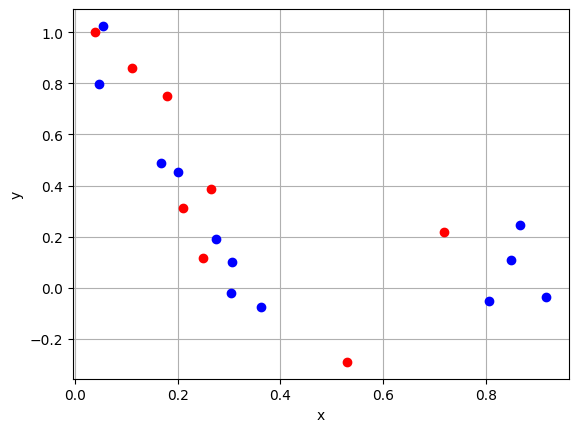

In [302]:
fig, ax = plt.subplots()
ax.plot(xl,yl, 'bo') # blue points to construct the model (learning)
ax.plot(xv,yv, 'ro') # red points to test the quality of the model (validation)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.grid() # acrivate the grid
plt.show()

In [303]:
# Choices I have to make:
# M - f'', |c|^2
# p
# lam
# -> I need to perform a greed search

err_best = +np.inf

for m in [0,1]:
  for p in range(0,14):
    for lam in np.logspace(-6,4,11):
      if (m==0):
        M = nml.zeros((p+1, p+1))

        for i in range(2, p+1):
          for j in range(2, p+1):
            M[i,j] = i * (i-1) * j * (j-1) / (i+j-3)
      else:
        M = nml.eye(p+1)

      X = nml.ones((nl,1))
      Xv = nml.ones((nv,1))

      for i in range (1, p+1):
        X = np.concatenate((X,np.power(xl,i)), axis=1)
        Xv = np.concatenate((Xv,np.power(xv,i)), axis=1)

      c = np.linalg.solve(X.T*X+lam*M, X.T*yl)
      yp = np.matmul(Xv,c)
      err = np.mean(np.power(yv-yp,2))

      if (err < err_best):
        err_best = err
        p_best = p
        m_best = m
        lam_best = lam
        yp_best = yp

print('p =', p_best)
print('m =', m_best)
print('lambda =', lam_best)

p = 4
m = 0
lambda = 1e-06


This last part cannot be done in practice -> we know the oracle system; otherwise, we need to stop before

In [304]:
nt = 1000 # we suppose to know it just because it's a toy example
xt = np.linspace(0,1,nt)
yt = oracle(xt)
xt = np.asmatrix(xt).transpose()
yt = np.asmatrix(yt).transpose()

p = p_best
m = m_best
lam = lam_best

if (m==0):
  M = nml.zeros((p+1, p+1))
  for i in range(2, p+1):
    for j in range(2, p+1):
      M[i,j] = i * (i-1) * j * (j-1) / (i+j-3)
else:
  M = nml.eye(p+1)

X = nml.ones((n,1))
Xt = nml.ones((nt,1))

for i in range (1, p+1):
  X = np.concatenate((X,np.power(x,i)), axis=1)
  Xt = np.concatenate((Xt,np.power(xt,i)), axis=1)

c = np.linalg.solve(X.T*X+lam*M, X.T*y)
yp = np.matmul(Xt,c)

Results:

1. Quadratic oracle (y = x**2)

sigma = 0, p = 2, m = 1, lam = 1e-06  

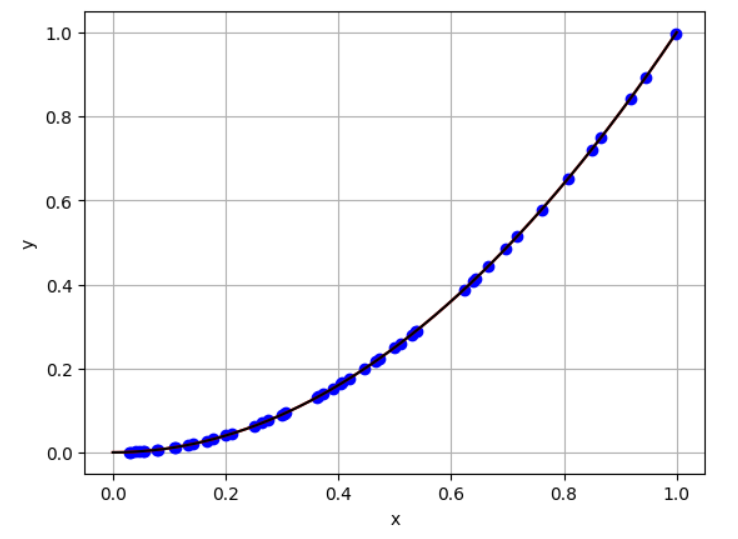

sigma = 0.1, p = 4, m = 1, lam = 0.1  

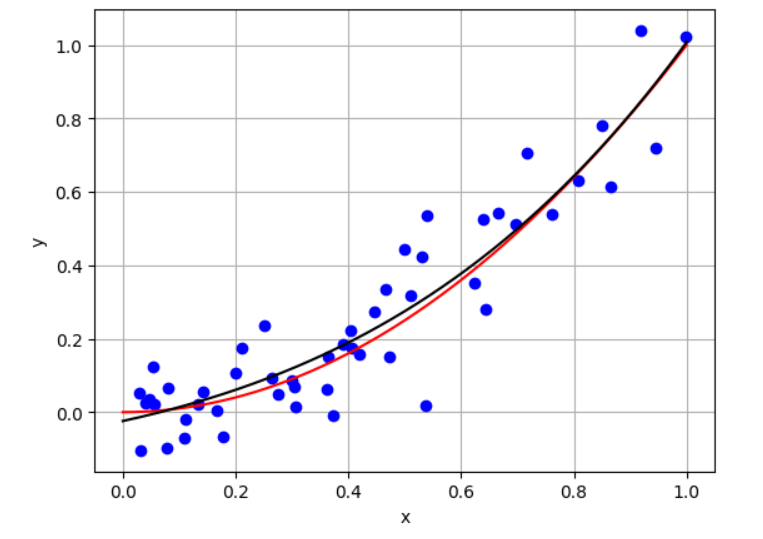

In [307]:
from IPython.display import Image, display

image_paths = [
    "/content/oracle1_sigma0.png",
    "/content/oracle1_sigma01.png"
]

sig = [0, 0.1]
p = [2, 4]
m = [1, 1]
lam = [1e-06, 0.1]

for i, path in enumerate(image_paths):
    print(f"sigma = {sig[i]}, p = {p[i]}, m = {m[i]}, lam = {lam[i]}", end="  ")
    display(Image(filename=path, width=300))


2. np.abs(np.abs(x-.4)-.2) + x/2-.1 oracle

sigma = 0, n = 10  

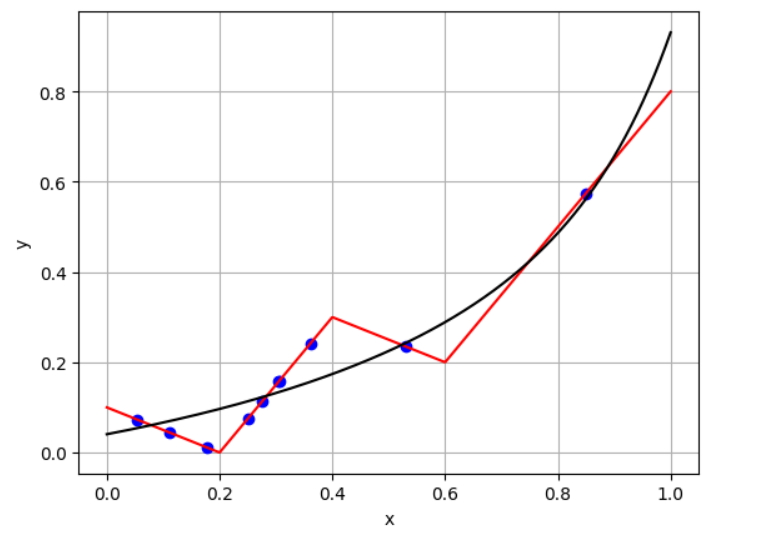

sigma = 0, n = 20  

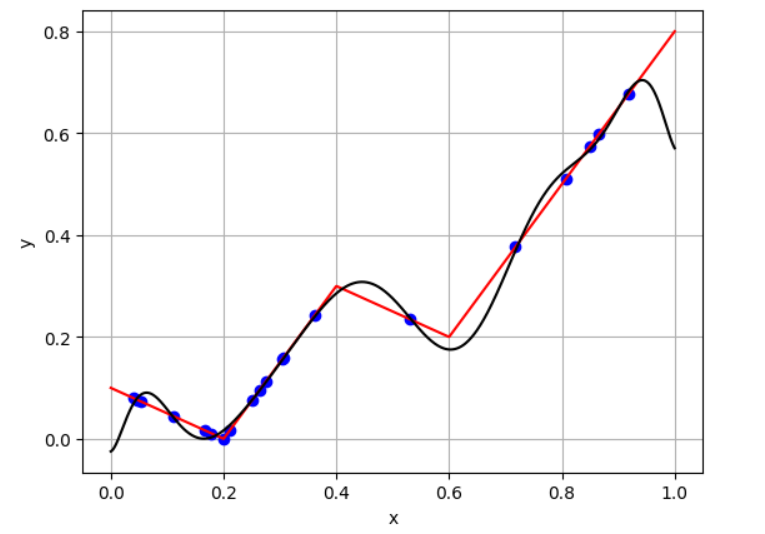

In [309]:
image_paths = [
    "/content/oracle2_sigma0_n10.png",
    "/content/oracle2_sigma0_n20.png"
]

n = [10, 20]

for i, path in enumerate(image_paths):
    print(f"sigma = 0, n = {n[i]}", end="  ")
    display(Image(filename=path, width=300))

3. Sinusoidal oracle

sigma = 0, n = 20, percentage of points in validation set = 0.2  

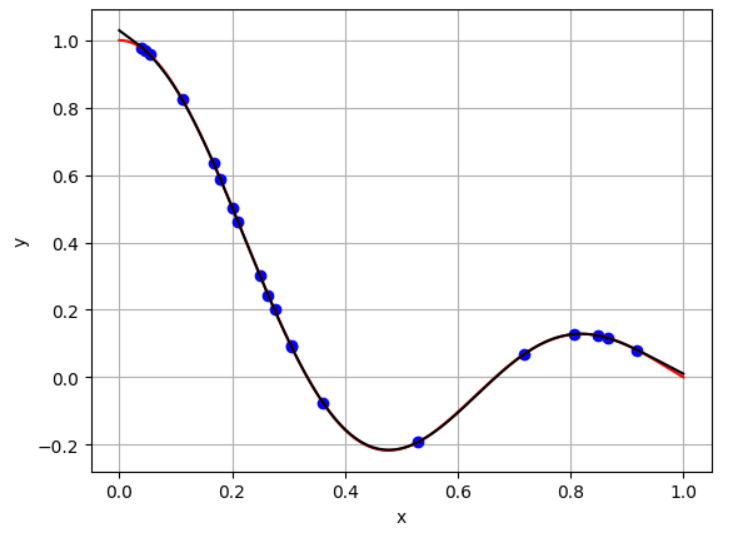

sigma = 0.1, n = 20, percentage of points in validation set = 0.2  

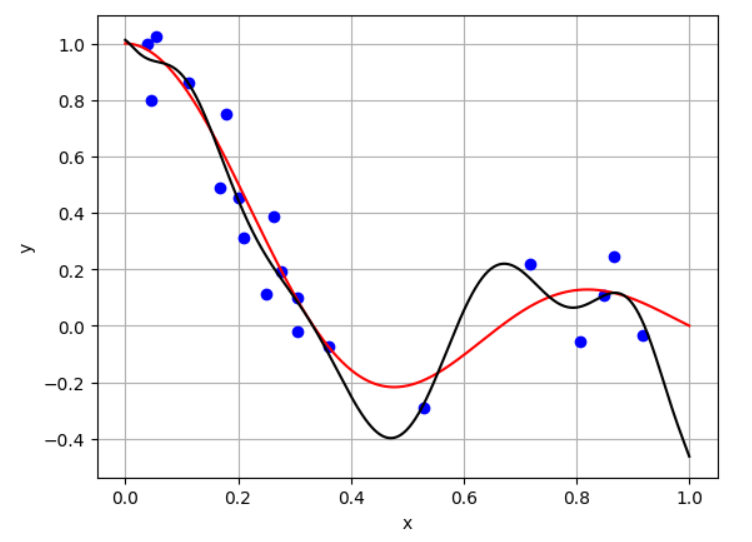

sigma = 0.1, n = 20, percentage of points in validation set = 0.4  

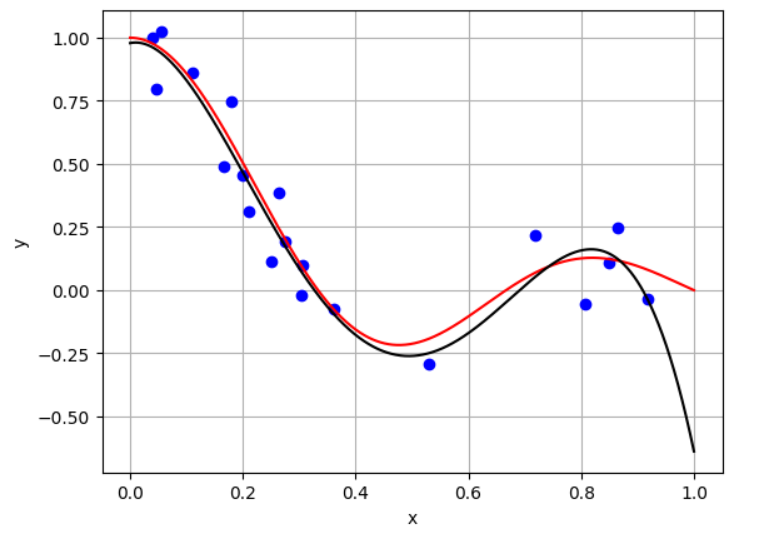

In [312]:
image_paths = [
    "/content/oracle3_sigma0_n20.png",
    "/content/oracle3_sigma01.png",
    "/content/oracle3_sigma01_val04.png"
]

sig = [0, 0.1, 0.1]
n = [20, 20, 20]
val = [0.2, 0.2, 0.4]

for i, path in enumerate(image_paths):
    print(f"sigma = {sig[i]}, n = {n[i]}, percentage of points in validation set = {val[i]}", end="  ")
    display(Image(filename=path, width=300))